# Joshua Fox
## CPSC 6420 - Fall 2026
## HW 2

In [136]:
#pip install "gymnasium[toy-text]"

# TAXI

In [137]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("Taxi-v4", render_mode="ansi")

### A - Environment description:
https://gymnasium.farama.org/environments/toy_text/taxi/

The goal is to pick up a passengar and drop them off at their destination.
The state space - the passengar could be in any of the following 5 locations (Red, Yellow, Green, Blue, or in the taxi). The taxi has 5x5=25 cells it could be and there are 4 possible drop-off locations. 5x25x4= 500 states. The info page tells us that there are actually only 404. The reason is that 25 cells x 3 possible drop-off locations since one is already a pickup location x 4 pickup locations =25x3x4 = 300 starting states. When the passenger is in the taxi there are 25 (cells) x 1 (current location) x 4 drop-off locations = 25x1x4 = 100 states when the rider is in the taxi. And finally there are 4 states when the passenger is dropped off sucessfully, resulting in 300 + 100 +4 = 404 actual states.
The action space is 6 actions, move north, move south, move east, move west, pick passenger, drop-off passenger.
The transition dynamics are deterministic and depend on the previous taxi position, passenger location, destination, and action.
The reward structure is +20 to deliver passenger, -1 per step (unless anothe reward is triggered), -10 executing pickup or drop-off action illegally.
The termination conditions are the taxi drops off the passenger or the episode is over 200.
State discretization/environment settings - already a discrete observation space


In [138]:
print("Number of states:", env.observation_space.n)
print("Number of actions:", env.action_space.n)
state, info = env.reset()
print("Current state:", state)
print(env.render())

Number of states: 500
Number of actions: 6
Current state: 353
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+




In [139]:
action = 5  # Move South

next_state, reward, terminated, truncated, info = env.step(action)

print("New state:", next_state)
print("Reward:", reward)
print("Terminated:", terminated)
print("Truncated:", truncated)

print(env.render())

New state: 353
Reward: -10
Terminated: False
Truncated: False
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)



### B - Implement Q-Learning
Q(s,a) <- Q(s,a) + $\alpha$ (r + $\gamma$max<sub>a'</sub> Q(s',a') - Q(s,a) )
Q Learning table for 500 (rounded from 404) states x 6 moves per state 500x6.

In [140]:
print("Number of states:", env.observation_space.n)
print("Number of actions:", env.action_space.n)
num_states = env.observation_space.n
num_actions = env.action_space.n

# Initialize Q-table with zeros
Q = np.zeros((num_states, num_actions))

print("Q-table shape:", Q.shape)

Number of states: 500
Number of actions: 6
Q-table shape: (500, 6)


### C - Baseline training
Initial testing shows that I needed to increase the learning rate and the discount factor. A high discount factor ended up being slower to really learn. I also needed to adjust expsilon decay to make sure I wasn't getting too many random actions while trying to improve the training.

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): 2.59


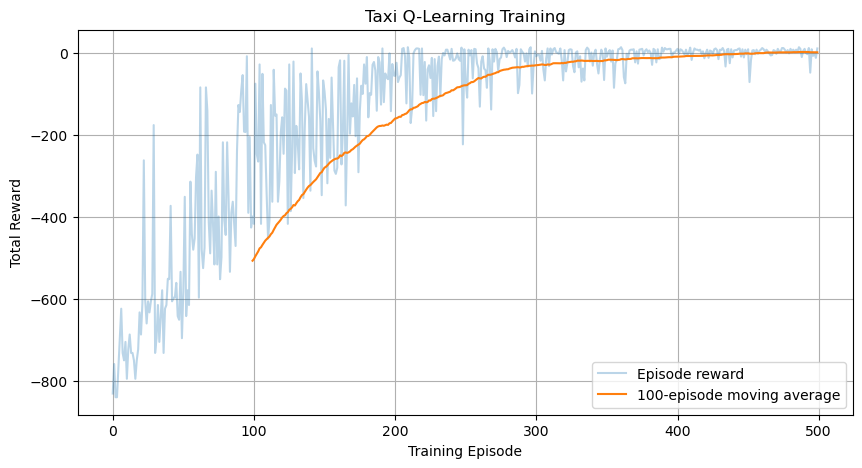

In [141]:
# Random Action function
def choose_action(state, Q, epsilon):
    if np.random.random() < epsilon:
        # Exploration: random action
        action = env.action_space.sample()
    else:
        # Exploitation: best known action
        action = np.argmax(Q[state])
    return action

def train_agent(episodes, alpha, gamma, epsilon, epsilon_decay, epsilon_min):
    # Initialize table and rewards
    Q = np.zeros((num_states, num_actions))
    episode_rewards = []
    for episode in range(episodes):
        state, info = env.reset()
        total_reward = 0
        done = False

        while not done:
            # Choose an action
            action = choose_action(state, Q, epsilon)
            # Perform the action
            next_state, reward, terminated, truncated, info = env.step(action)
            # 3. Calculate the best future Q-value
            if terminated:
                best_next_q = 0
            else:
                best_next_q = np.max(Q[next_state])
            # Update Q-value
            Q[state, action] = Q[state, action] + alpha * (
                reward + gamma * best_next_q - Q[state, action]
            )
            # Update state
            state = next_state
            # Accumulate rewards
            total_reward += reward
            # Check whether episode ended
            done = terminated or truncated

        # Save episode reward
        episode_rewards.append(total_reward)
        # Decrease epsilon after each episode
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    print("Training complete!")
    print("Final epsilon:", epsilon)
    print("Average reward (last 100 episodes):",
        np.mean(episode_rewards[-100:]))

    plt.figure(figsize=(10, 5))

    plt.plot(episode_rewards, alpha=0.3, label="Episode reward")

    # Moving average over 100 episodes
    moving_average = np.convolve(
        episode_rewards,
        np.ones(100) / 100,
        mode="valid"
    )

    plt.plot(
        range(99, len(episode_rewards)),
        moving_average,
        label="100-episode moving average"
    )

    plt.xlabel("Training Episode")
    plt.ylabel("Total Reward")
    plt.title("Taxi Q-Learning Training")
    plt.legend()
    plt.grid(True)
    plt.show()
    return Q, episode_rewards

# Hyperparameters
alpha = 0.4
gamma = 0.8
epsilon = 1.0
epsilon_decay = 0.99
epsilon_min = 0.01
episodes = 500

Q_init, rewards_init = train_agent(episodes, alpha, gamma, epsilon, epsilon_decay, epsilon_min)

### D - Learning-rate experiment
The greater the alpha (learning rate), the faster it gets up to speed before it begins to plateu.

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): 7.01


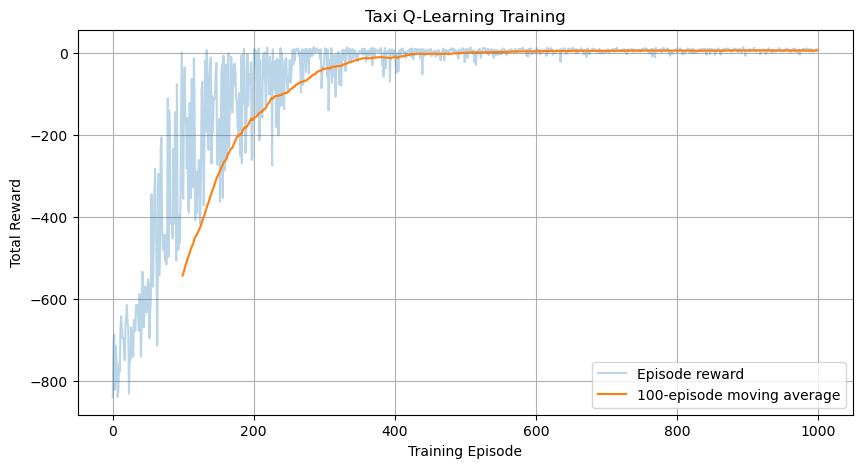

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): 5.0


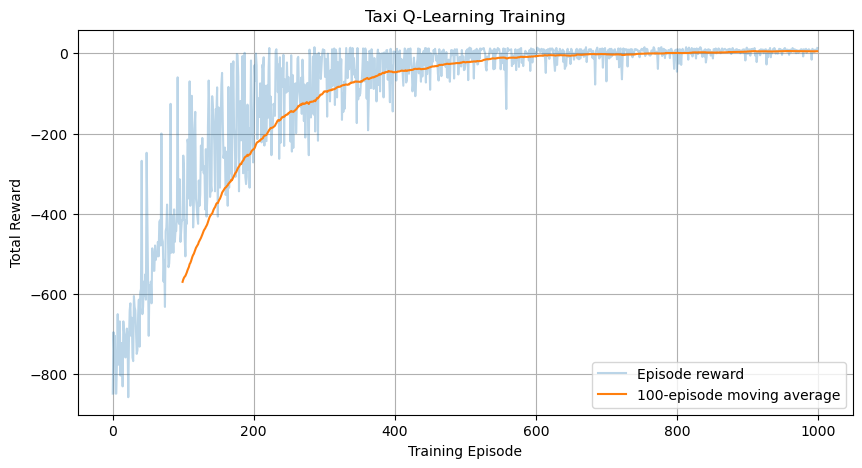

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): 7.53


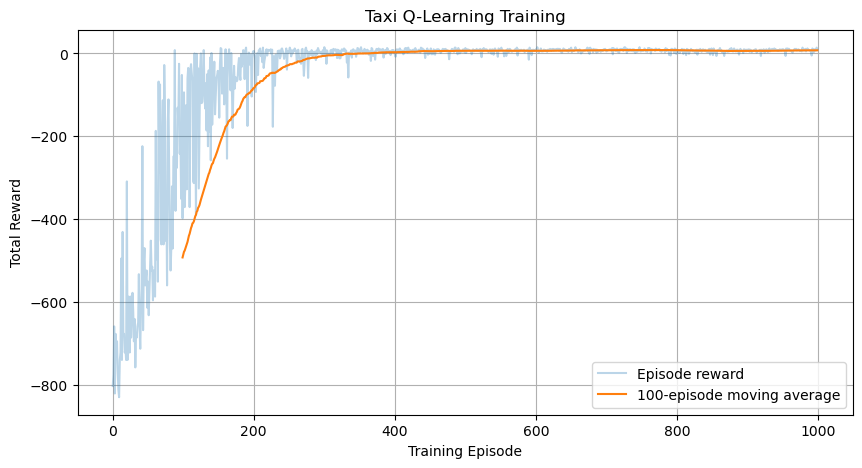

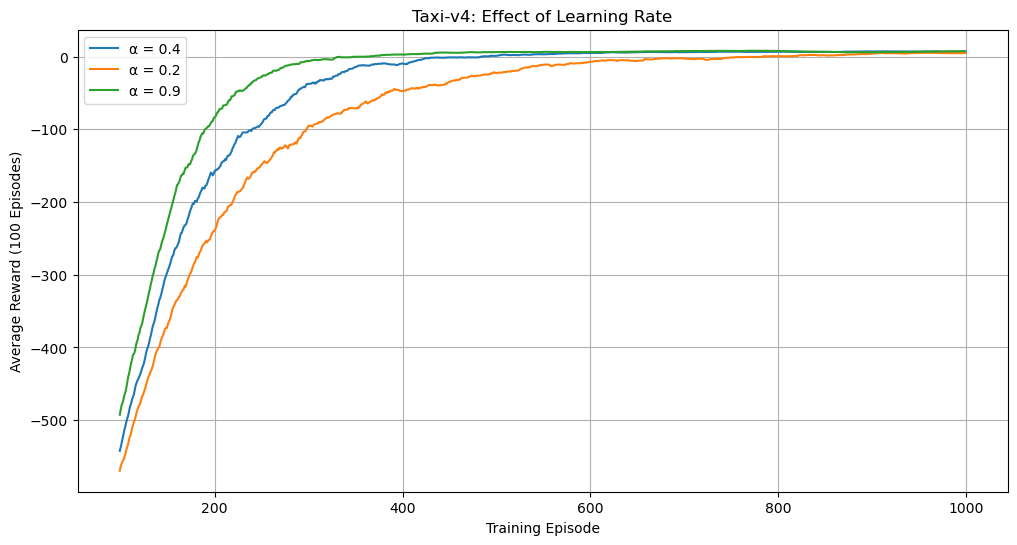

In [142]:
# Hyperparameters
alpha1 = 0.4
gamma1 = 0.8
epsilon1 = 1.0
epsilon_decay1 = 0.99
epsilon_min1 = 0.01
episodes1 = 1000

Q1, rewards1 = train_agent(episodes1, alpha1, gamma1, epsilon1, epsilon_decay1, epsilon_min1)

# Hyperparameters
alpha2 = 0.2
gamma2 = 0.8
epsilon2 = 1.0
epsilon_decay2 = 0.99
epsilon_min2 = 0.01
episodes2 = 1000

Q2, rewards2 = train_agent(episodes2, alpha2, gamma2, epsilon2, epsilon_decay2, epsilon_min2)

# Hyperparameters
alpha3 = 0.9
gamma3 = 0.8
epsilon3 = 1.0
epsilon_decay3 = 0.99
epsilon_min3 = 0.01
episodes3 = 1000

Q3, rewards3 = train_agent(episodes3, alpha3, gamma3, epsilon3, epsilon_decay3, epsilon_min3)

# Combined Plot
def moving_average(rewards, window=100):
    return np.convolve(
        rewards,
        np.ones(window) / window,
        mode="valid"
    )

plt.figure(figsize=(12, 6))

plt.plot(
    range(99, len(rewards1)),
    moving_average(rewards1),
    label="α = 0.4"
)

plt.plot(
    range(99, len(rewards2)),
    moving_average(rewards2),
    label="α = 0.2"
)

plt.plot(
    range(99, len(rewards3)),
    moving_average(rewards3),
    label="α = 0.9"
)

plt.xlabel("Training Episode")
plt.ylabel("Average Reward (100 Episodes)")
plt.title("Taxi-v4: Effect of Learning Rate")
plt.legend()
plt.grid(True)
plt.show()

### E Discount-factor 
The lower discount factor took slightly longer to plateu, but ended up with a higher average at the end of learning.

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): 6.49


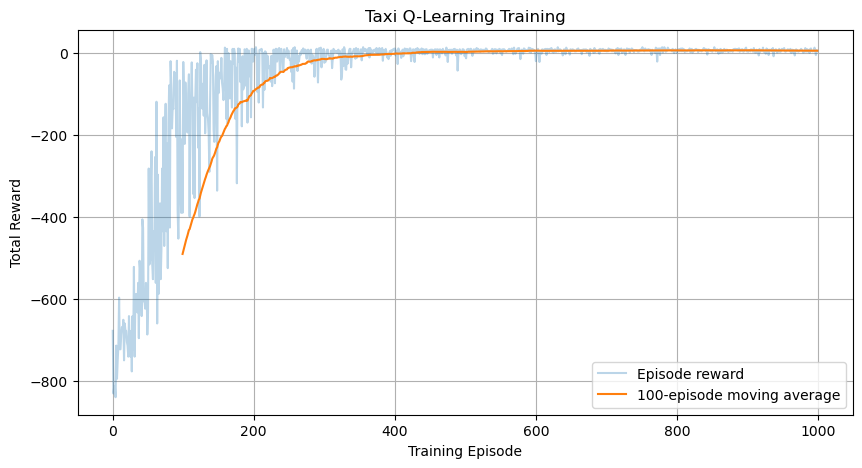

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): 6.8


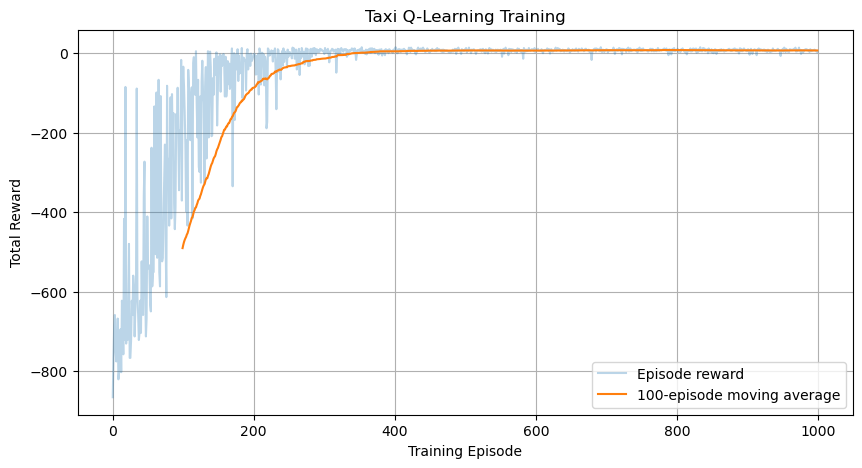

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): 7.58


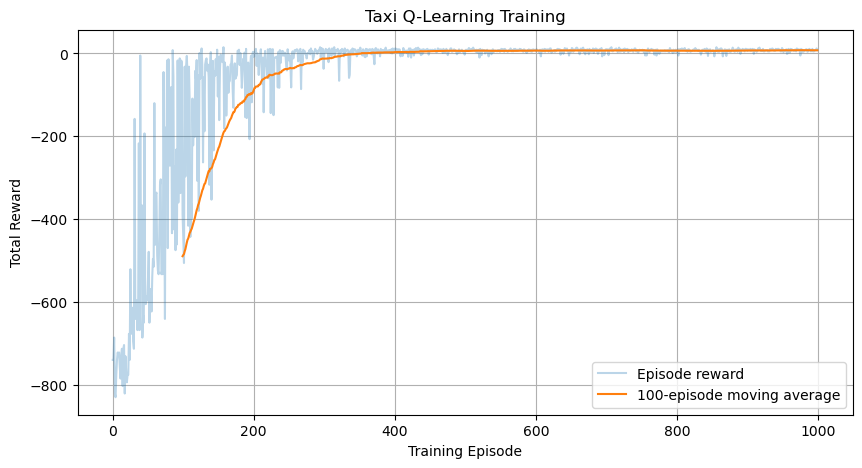

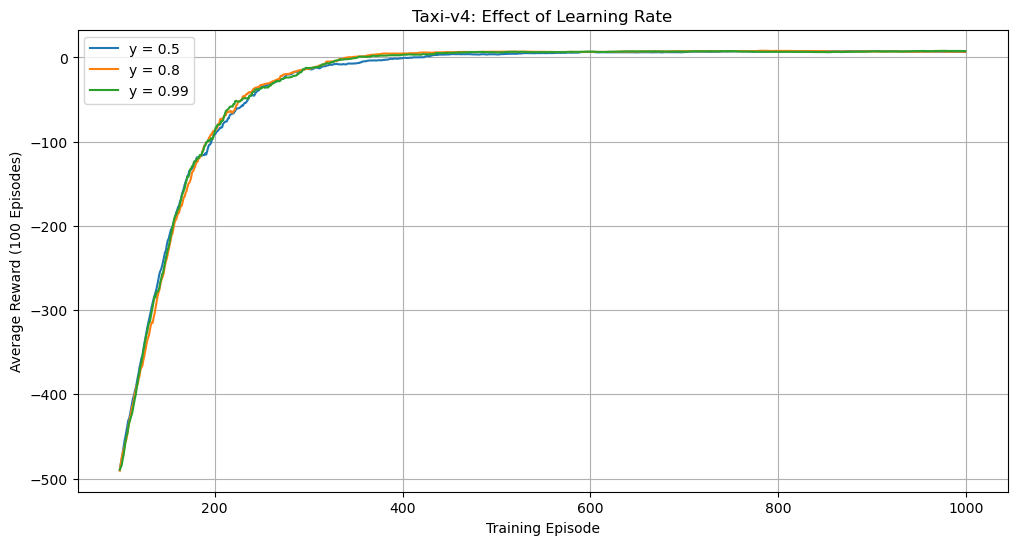

In [143]:
# Hyperparameters
alpha1 = 0.8
gamma1 = 0.5
epsilon1 = 1.0
epsilon_decay1 = 0.99
epsilon_min1 = 0.01
episodes1 = 1000

Q1, rewards1 = train_agent(episodes1, alpha1, gamma1, epsilon1, epsilon_decay1, epsilon_min1)

# Hyperparameters
alpha2 = 0.8
gamma2 = 0.8
epsilon2 = 1.0
epsilon_decay2 = 0.99
epsilon_min2 = 0.01
episodes2 = 1000

Q2, rewards2 = train_agent(episodes2, alpha2, gamma2, epsilon2, epsilon_decay2, epsilon_min2)

# Hyperparameters
alpha3 = 0.8
gamma3 = 0.99
epsilon3 = 1.0
epsilon_decay3 = 0.99
epsilon_min3 = 0.01
episodes3 = 1000

Q3, rewards3 = train_agent(episodes3, alpha3, gamma3, epsilon3, epsilon_decay3, epsilon_min3)

# Combined Plot
def moving_average(rewards, window=100):
    return np.convolve(
        rewards,
        np.ones(window) / window,
        mode="valid"
    )

plt.figure(figsize=(12, 6))

plt.plot(
    range(99, len(rewards1)),
    moving_average(rewards1),
    label="y = 0.5"
)

plt.plot(
    range(99, len(rewards2)),
    moving_average(rewards2),
    label="y = 0.8"
)

plt.plot(
    range(99, len(rewards3)),
    moving_average(rewards3),
    label="y = 0.99"
)

plt.xlabel("Training Episode")
plt.ylabel("Average Reward (100 Episodes)")
plt.title("Taxi-v4: Effect of Learning Rate")
plt.legend()
plt.grid(True)
plt.show()

### F - One additional hyperparameter
Dropping epsilon decay down to 0.9 has higher initial numbers, getting us to the plateu faster, but the average over the final 100 episodes is slightly lower. This means at the end of training we are getting slightly lower scores with a lower eopsilon decay.

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): 6.72


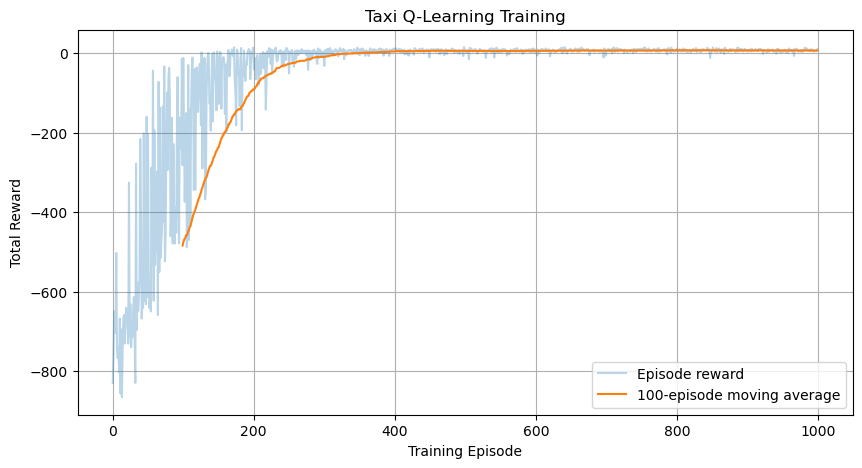

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): 6.92


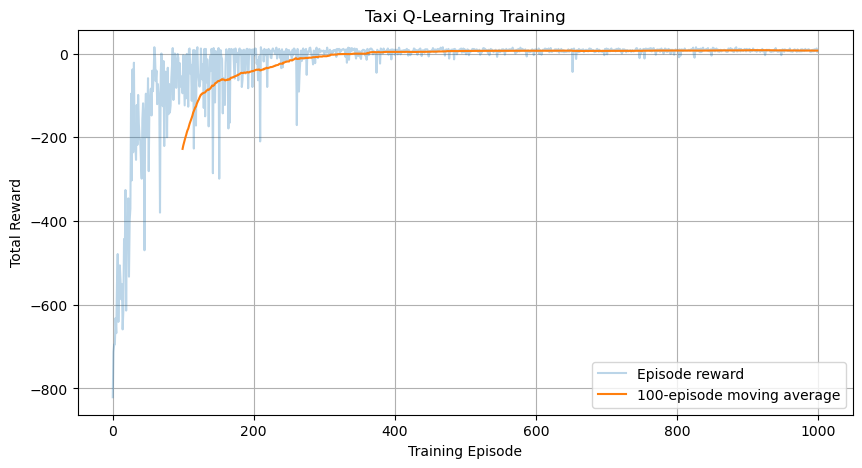

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): 7.41


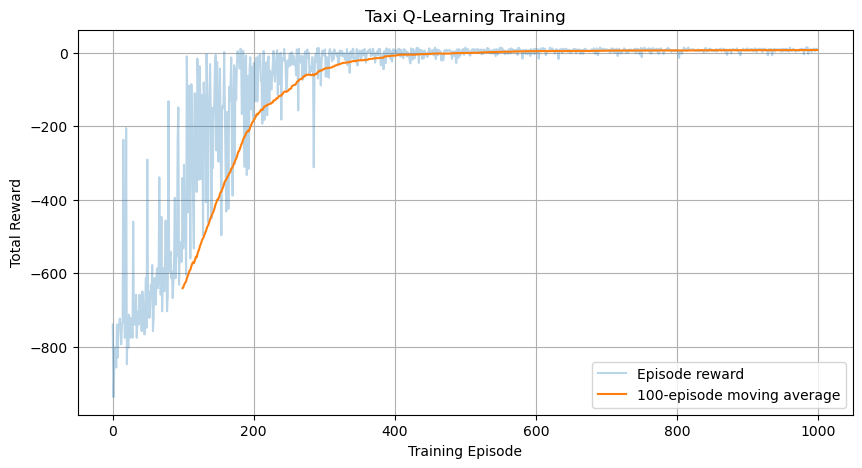

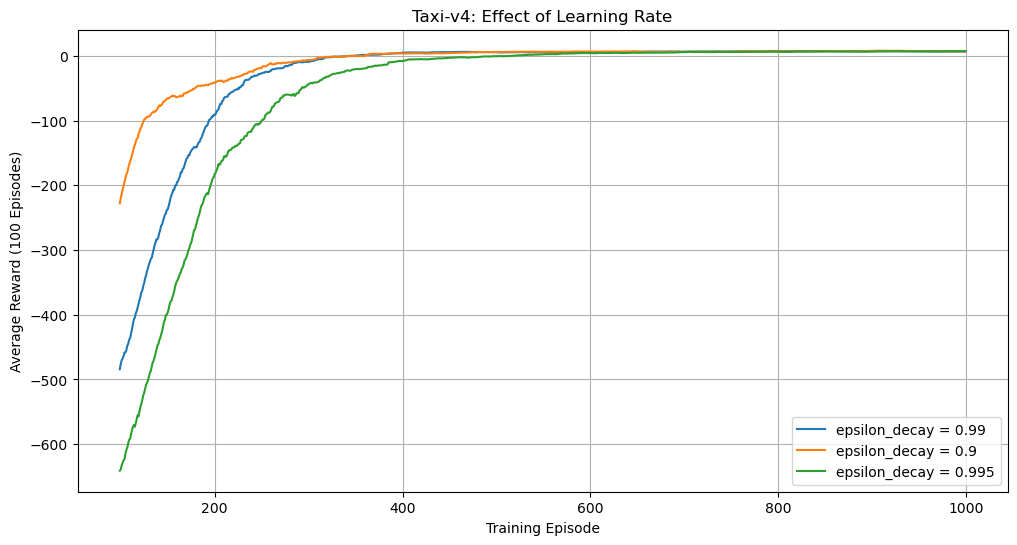

In [144]:
# Hyperparameters
alpha1 = 0.8
gamma1 = 0.99
epsilon1 = 1.0
epsilon_decay1 = 0.99
epsilon_min1 = 0.01
episodes1 = 1000

Q1, rewards1 = train_agent(episodes1, alpha1, gamma1, epsilon1, epsilon_decay1, epsilon_min1)

# Hyperparameters
alpha2 = 0.8
gamma2 = 0.99
epsilon2 = 1.0
epsilon_decay2 = 0.9
epsilon_min2 = 0.01
episodes2 = 1000

Q2, rewards2 = train_agent(episodes2, alpha2, gamma2, epsilon2, epsilon_decay2, epsilon_min2)

# Hyperparameters
alpha3 = 0.8
gamma3 = 0.99
epsilon3 = 1.0
epsilon_decay3 = 0.995
epsilon_min3 = 0.01
episodes3 = 1000

Q3, rewards3 = train_agent(episodes3, alpha3, gamma3, epsilon3, epsilon_decay3, epsilon_min3)
Q_best = Q3  # Assuming the best Q-table is from the last training session
# Combined Plot
def moving_average(rewards, window=100):
    return np.convolve(
        rewards,
        np.ones(window) / window,
        mode="valid"
    )

plt.figure(figsize=(12, 6))

plt.plot(
    range(99, len(rewards1)),
    moving_average(rewards1),
    label="epsilon_decay = 0.99"
)

plt.plot(
    range(99, len(rewards2)),
    moving_average(rewards2),
    label="epsilon_decay = 0.9"
)

plt.plot(
    range(99, len(rewards3)),
    moving_average(rewards3),
    label="epsilon_decay = 0.995"
)

plt.xlabel("Training Episode")
plt.ylabel("Average Reward (100 Episodes)")
plt.title("Taxi-v4: Effect of Learning Rate")
plt.legend()
plt.grid(True)
plt.show()

### Evaluate your best agent
100% Success rate!

In [146]:
def evaluate_agent(Q, episodes=100):

    rewards = []
    steps_list = []
    successes = 0

    for episode in range(episodes):

        state, info = env.reset()

        total_reward = 0
        steps = 0
        done = False

        while not done:

            # Exploitation only (epsilon = 0)
            action = np.argmax(Q[state])

            # Execute action
            next_state, reward, terminated, truncated, info = env.step(action)

            total_reward += reward
            steps += 1

            state = next_state
            done = terminated or truncated

            if terminated:
                successes += 1

        rewards.append(total_reward)
        steps_list.append(steps)

    # Calculate performance metrics
    mean_reward = np.mean(rewards)
    success_rate = successes / episodes * 100
    mean_steps = np.mean(steps_list)

    print(f"Episodes evaluated: {episodes}")
    print(f"Mean reward: {mean_reward:.2f}")
    print(f"Success rate: {success_rate:.1f}%")
    print(f"Mean steps: {mean_steps:.2f}")

    return mean_reward, success_rate, mean_steps
#Best hyperparameters found from previous experiments

print("Best hyperparameters results:")
best_results = evaluate_agent(Q_best, episodes=100)
print("Baseline hyperparameters results:")
baseline_results = evaluate_agent(Q_init, episodes=100)

Best hyperparameters results:
Episodes evaluated: 100
Mean reward: 7.80
Success rate: 100.0%
Mean steps: 13.20
Baseline hyperparameters results:
Episodes evaluated: 100
Mean reward: -80.45
Success rate: 57.0%
Mean steps: 92.42


### H - Stochastic environment
With added noise it struggles and is not always successful!

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): 7.21


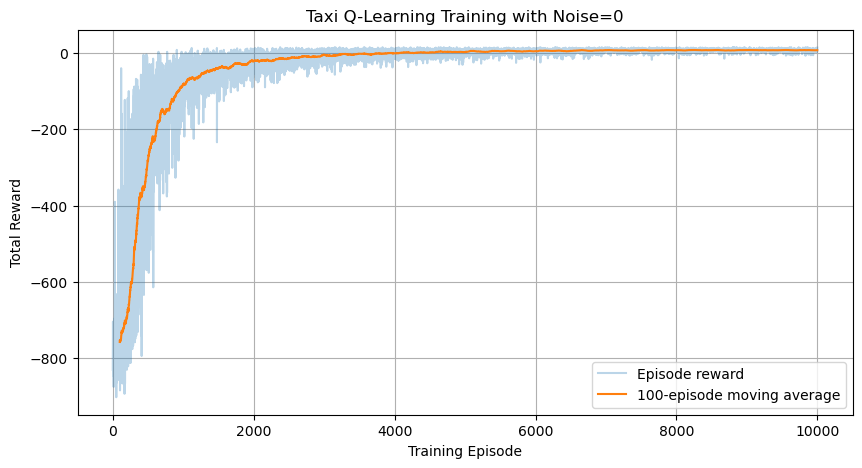

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): -5.23


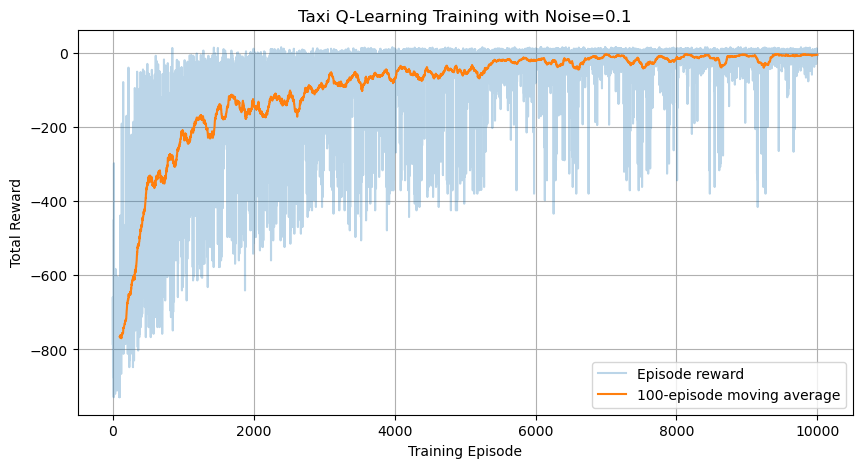

Training complete!
Final epsilon: 0.01
Average reward (last 100 episodes): -89.88


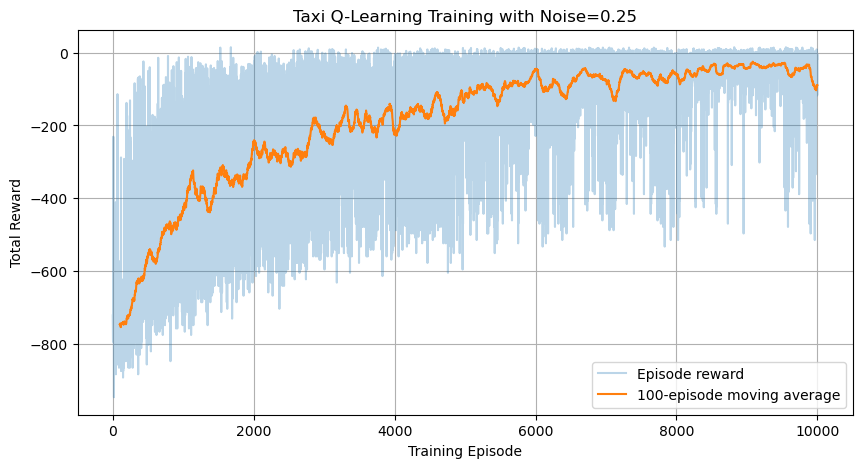

In [148]:
def noisy_action(action, noise, num_actions=6):

    if np.random.random() < noise:

        # Select a different action
        other_actions = [
            a for a in range(num_actions)
            if a != action
        ]

        return np.random.choice(other_actions)

    return action

def train_agent(episodes, alpha, gamma, epsilon, epsilon_decay, epsilon_min, noise=0):

    # Initialize table and rewards
    Q = np.zeros((num_states, num_actions))
    episode_rewards = []

    for episode in range(episodes):

        state, info = env.reset()
        total_reward = 0
        done = False

        while not done:

            # Choose an action
            action = choose_action(state, Q, epsilon)

            # Add noise to the action
            actual_action = noisy_action(action, noise)

            # Perform the action
            next_state, reward, terminated, truncated, info = env.step(actual_action)

            # Calculate the best future Q-value
            if terminated:
                best_next_q = 0
            else:
                best_next_q = np.max(Q[next_state])

            # Update Q-value for the INTENDED action
            Q[state, action] = Q[state, action] + alpha * (
                reward + gamma * best_next_q - Q[state, action]
            )

            # Update state
            state = next_state

            # Accumulate rewards
            total_reward += reward

            # Check whether episode ended
            done = terminated or truncated

        # Save episode reward
        episode_rewards.append(total_reward)

        # Decrease epsilon after each episode
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    print("Training complete!")
    print("Final epsilon:", epsilon)
    print("Average reward (last 100 episodes):",
          np.mean(episode_rewards[-100:]))

    plt.figure(figsize=(10, 5))

    plt.plot(episode_rewards, alpha=0.3, label="Episode reward")

    # Moving average over 100 episodes
    moving_average = np.convolve(
        episode_rewards,
        np.ones(100) / 100,
        mode="valid"
    )

    plt.plot(
        range(99, len(episode_rewards)),
        moving_average,
        label="100-episode moving average"
    )

    plt.xlabel("Training Episode")
    plt.ylabel("Total Reward")
    plt.title(f"Taxi Q-Learning Training with Noise={noise}")
    plt.legend()
    plt.grid(True)
    plt.show()

    return Q, episode_rewards


episodes = 10000
alpha = 0.8
gamma = 0.99
epsilon = 1.0
epsilon_decay = 0.9995
epsilon_min = 0.01

# Deterministic environment
Q0, rewards0 = train_agent(
    episodes, alpha, gamma, epsilon,
    epsilon_decay, epsilon_min, noise=0
)

# 10% action noise
Q10, rewards10 = train_agent(
    episodes, alpha, gamma, epsilon,
    epsilon_decay, epsilon_min, noise=0.10
)

# 25% action noise
Q25, rewards25 = train_agent(
    episodes, alpha, gamma, epsilon,
    epsilon_decay, epsilon_min, noise=0.25
)